# 3. Rebuild attention and test what it can see

**Goal:** compute a tiny attention operation by hand-sized tensors, then verify an actual transformer cannot use future tokens. This lesson is independent.

### Definitions

| Term | Definition |
|---|---|
| Query (Q) | A projected vector used to match this position against others |
| Key (K) | A projected vector used when other positions match this position |
| Value (V) | A projected vector whose information is mixed into the output |
| Dot product | Multiply corresponding entries and sum; here it produces a matching score |
| Attention weights | Softmax-normalized matching scores over allowed positions |
| Causal mask | Excludes future input positions from each prediction |
| Head | One independently projected attention calculation |
| Multi-head attention | Multiple heads whose results are combined |
| Residual connection | Add a layer's input back to its output |
| LayerNorm | Normalize feature values within a position, with learned scale/offset |
| Feed-forward network | A small nonlinear network applied separately at each position |

The familiar Q/K/V metaphors are memory aids. They are learned linear projections, not literal questions or facts. Attention weights alone do not fully explain a model's reasoning.

In [1]:
from pathlib import Path
import sys

# Find the lesson folder from the notebook folder, mini_llm, or repository root.
candidates = [Path.cwd(), Path.cwd() / "learning_path",
              Path.cwd() / "mini_llm" / "learning_path"]
lesson_dir = next((p.resolve() for p in candidates if (p / "lab.py").is_file()), None)
if lesson_dir is None:
    raise FileNotFoundError("Open this notebook from learning_path, mini_llm, or the repository root.")
if str(lesson_dir) not in sys.path:
    sys.path.insert(0, str(lesson_dir))

import math
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import lab

torch.set_num_threads(2)
torch.manual_seed(42)
print("Local CPU lesson | PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Local CPU lesson | PyTorch 2.14.1


### Step A — compare, mask, normalize, mix
We use invented vectors so every number is inspectable. `Q @ K.T / sqrt(head_dimension)` produces scores. Replace future scores with negative infinity **before** softmax; those positions receive zero probability.

A row may read its own position because the target is the following token, not the current input token.

In [2]:
q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
k = torch.tensor([[1., 0.], [0., 1.], [1., 0.]])
v = torch.tensor([[10., 0.], [0., 20.], [30., 30.]])
scores = q @ k.T / math.sqrt(q.shape[-1])
allowed = torch.tril(torch.ones(3, 3, dtype=torch.bool))
weights = scores.masked_fill(~allowed, float("-inf")).softmax(-1)
output = weights @ v
print("Raw scores:\n", scores)
print("Attention weights:\n", weights)
print("Weighted values:\n", output)
assert torch.count_nonzero(torch.triu(weights, diagonal=1)) == 0
torch.testing.assert_close(weights.sum(-1), torch.ones(3))
torch.testing.assert_close(output[0], v[0])

Raw scores:
 tensor([[0.7071, 0.0000, 0.7071],
        [0.0000, 0.7071, 0.0000],
        [0.7071, 0.7071, 0.7071]])
Attention weights:
 tensor([[1.0000, 0.0000, 0.0000],
        [0.3302, 0.6698, 0.0000],
        [0.3333, 0.3333, 0.3333]])
Weighted values:
 tensor([[10.0000,  0.0000],
        [ 3.3024, 13.3952],
        [13.3333, 16.6667]])


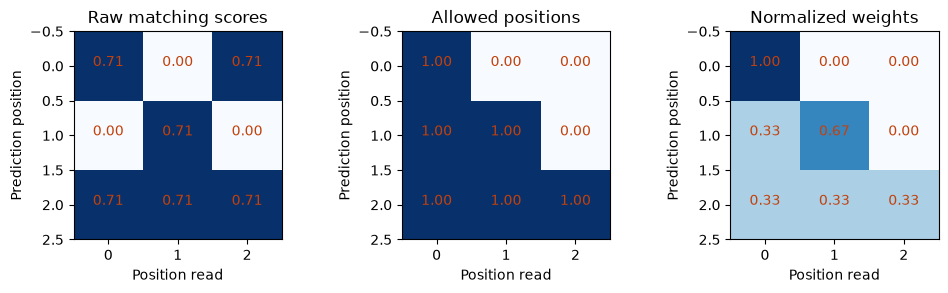

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, matrix, title in zip(axes, [scores, allowed.float(), weights],
                           ["Raw matching scores", "Allowed positions", "Normalized weights"]):
    image = ax.imshow(matrix.numpy(), cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Position read"); ax.set_ylabel("Prediction position")
    for i in range(3):
        for j in range(3): ax.text(j, i, f"{float(matrix[i,j]):.2f}", ha="center", color="#c2410c")
plt.tight_layout(); plt.show()

### Step B — inspect multi-head shapes
Open `CausalSelfAttention.forward` in `lab.py`. It follows the same four steps, but learns Q/K/V and handles batches and heads.

For width 48 and three heads, each head gets 16 features. The scores have shape `(batch, heads, time, time)`. Combining heads restores width 48; it does not increase the number of token positions.

In [4]:
config = lab.Config()
attention = lab.CausalSelfAttention(config)
x = torch.randn(2, 6, config.embedding_dim)
out, learned_weights = attention(x, return_weights=True)
print("Input:", tuple(x.shape))
print("Attention weights:", tuple(learned_weights.shape))
print("Output:", tuple(out.shape))
assert learned_weights.shape == (2, 3, 6, 6)
assert out.shape == x.shape

Input: (2, 6, 48)
Attention weights: (2, 3, 6, 6)
Output: (2, 6, 48)


### Step C — challenge the whole transformer
A mask-looking picture is not proof. Change future token IDs and check that earlier logits remain identical. Use evaluation mode so dropout does not inject random differences.

Then replace the causal mask with an all-visible mask temporarily: the same test should detect leakage. This is an intentionally broken local model used only for this demonstration.

In [5]:
torch.manual_seed(42)
model = lab.SinoLM(config).eval()
original = torch.tensor([lab.encode("the cat")])
changed = original.clone(); changed[:, 4:] = (changed[:, 4:] + 7) % len(lab.CHARS)
with torch.no_grad():
    before = model(original)[0][:, :4]
    after = model(changed)[0][:, :4]
causal_difference = float((before-after).abs().max())
torch.testing.assert_close(before, after, atol=1e-6, rtol=1e-6)

import copy
broken = copy.deepcopy(model)
for block in broken.blocks: block.attention.mask.fill_(True)
with torch.no_grad():
    broken_difference = float((broken(original)[0][:, :4] - broken(changed)[0][:, :4]).abs().max())
assert broken_difference > 1e-5
print("Maximum earlier-logit change with proper mask:", causal_difference)
print("Maximum earlier-logit change with broken mask:", broken_difference)

Maximum earlier-logit change with proper mask: 0.0
Maximum earlier-logit change with broken mask: 0.21195095777511597


### Check your understanding

Why does attention scale scores by the square root of head size? What changes if we mask after softmax?

<details><summary>Suggested answer — try first</summary>

Scaling helps control score magnitude as vector dimension grows. Masking after softmax without renormalization leaves rows summing to less than one. Masking before normalization makes allowed weights form a probability distribution.

</details>

### Your exercises
1. Change `num_heads` from 3 to 6 with width 48. Predict the head dimension and weight shape.
2. Explain why width 48 with five heads is rejected.
3. Write the four attention operations in your own function, then compare its output to the worked calculation.
4. Read `Block.forward`: identify attention mixing across positions, the per-position network, and the two residual additions.

**Completion criterion:** implement the small attention calculation yourself and reproduce both the passing causal test and the deliberately failing unmasked case.

Reference: [PyTorch attention reference](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html). Next: [04 — Reliable experiments](04_reliable_experiments.ipynb).